<a href="https://colab.research.google.com/github/nabillahumi/S5-Mesin_Learning/blob/main/Jobsheet3%20PBL/Praktikum%201%20(JS3)%20PBL%20(gabungan%20data).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Langkah 1 - Memuat Kedua Dataset

In [1]:
import pandas as pd

# Memuat dataset kafe dan ulasan
df_cafes = pd.read_csv('cafes.csv')
df_reviews = pd.read_csv('reviews.csv')

# Menampilkan informasi ringkas bentuk data
print("Dimensi Cafes:", df_cafes.shape)
print("Dimensi Reviews:", df_reviews.shape)

# Menampilkan 2 baris teratas masing-masing dataset
display(df_cafes.head(2))
display(df_reviews.head(2))

Dimensi Cafes: (99, 12)
Dimensi Reviews: (2230, 8)


,cafe_id,name,address,latitude,longitude,rating,review_count,categories,phone,website,scraped_at,source_query
0,ba4b512c-fa2d-4959-8384-8570c81121ec,ARTE COFFEE & EATERY,"Jl. Semeru No.80, Oro-oro Dowo, Kec. Klojen, K...",-7.972556,112.622708,4.7,528,['Kedai Kopi'],0821-3299-9938,instagram.com,2026-10-11T13:54:39.597643,cafe Kota Malang
1,528dfd21-83c6-4946-ab05-391e238caa4a,Nayanika Coffee & Eatery - Malang,"Jl. Brigjend Slamet Riadi No.173, Oro-oro Dowo...",-7.963825,112.627146,4.7,141,['Kafe'],0851-4820-4378,linktr.ee,2026-10-11T13:54:56.561971,cafe Kota Malang


,review_id,cafe_id,author_name,rating,text,published_at,likes,scraped_at
0,21314615-664d-438a-9f68-142f5b13f4c9,ba4b512c-fa2d-4959-8384-8570c81121ec,Alicia K. Taruli Manurung,5.0,Hore!,11 menit lalu,0,2026-10-11T13:54:49.423310
1,ec085c18-dced-4c23-8a65-4f71f93ed181,ba4b512c-fa2d-4959-8384-8570c81121ec,seobchwi fb,5.0,Pelayanan bagus dan ramah apalagi barista yg p...,14 menit lalu,0,2026-10-11T13:54:49.622536


#Langkah 2 - Agregasi Fitur Teks dari Dataset Ulasan (reviews.csv)

In [2]:
# Menghitung panjang karakter dari setiap teks ulasan
df_reviews['text_len'] = df_reviews['text'].fillna('').str.len()

# Melakukan agregasi per cafe_id
agg_reviews = df_reviews.groupby('cafe_id').agg(
    avg_review_rating=('rating', 'mean'),             # Rata-rata rating dari ulasan pelanggan
    total_likes=('likes', 'sum'),                     # Total likes yang diperoleh kafe
    avg_review_length=('text_len', 'mean'),           # Rata-rata panjang teks ulasan (tingkat detail review)
    extracted_review_count=('review_id', 'count')     # Jumlah total ulasan yang tercatat
).reset_index()

# Menampilkan hasil agregasi teratas
agg_reviews.head()

,cafe_id,avg_review_rating,total_likes,avg_review_length,extracted_review_count
0,0085521b-e46c-43bc-8e9c-c1ed99e6ac2f,4.400000,0,119.400000,30
1,010536ad-dbdd-4529-b30b-b2b2dd5e1c76,4.750000,10,89.550000,20
2,019fdd76-28e6-46c2-a37b-7b84cac1396b,4.166667,0,158.733333,30
3,033b9721-a897-4ac0-8f60-83c0861918f7,5.000000,0,63.500000,2
4,05735258-1db3-4fd8-b881-9ccb5affc0e7,4.200000,0,106.033333,30


#Langkah 3 - Menggabungkan Kedua Dataset (Merging)

In [3]:
# Menggabungkan data kafe dengan hasil agregasi ulasan menggunakan left join
df_combined = pd.merge(df_cafes, agg_reviews, on='cafe_id', how='left')

# Menampilkan beberapa kolom hasil penggabungan
df_combined[['name', 'rating', 'avg_review_rating', 'total_likes', 'extracted_review_count']].head()

,name,rating,avg_review_rating,total_likes,extracted_review_count
0,ARTE COFFEE & EATERY,4.7,4.400000,0.0,30.0
1,Nayanika Coffee & Eatery - Malang,4.7,4.866667,0.0,30.0
2,The Grove Cafe Malang,4.6,4.217391,0.0,23.0
3,Zocco Heritage,4.3,4.133333,0.0,30.0
4,RASWARA COFFEE AND EATERY,4.3,3.666667,0.0,30.0


#Langkah 4 - Ekstraksi Fitur Tambahan Berbasis Hasil Gabungan

In [4]:
import numpy as np

# 1. rating_diff: Selisih antara rating profil kafe dengan rata-rata rating review
df_combined['rating_diff'] = df_combined['rating'] - df_combined['avg_review_rating']

# 2. ReviewLengthCategory: Mengelompokkan rata-rata panjang ulasan (Short, Medium, Long)
df_combined['ReviewLengthCategory'] = pd.cut(
    df_combined['avg_review_length'],
    bins=[0, 50, 150, 500],
    labels=['Short', 'Medium', 'Long']
)

print("✅ Ekstraksi Fitur Gabungan Selesai!")
df_combined[['name', 'rating', 'avg_review_rating', 'rating_diff', 'ReviewLengthCategory']].head()

✅ Ekstraksi Fitur Gabungan Selesai!


,name,rating,avg_review_rating,rating_diff,ReviewLengthCategory
0,ARTE COFFEE & EATERY,4.7,4.400000,0.300000,Medium
1,Nayanika Coffee & Eatery - Malang,4.7,4.866667,-0.166667,Medium
2,The Grove Cafe Malang,4.6,4.217391,0.382609,Long
3,Zocco Heritage,4.3,4.133333,0.166667,Medium
4,RASWARA COFFEE AND EATERY,4.3,3.666667,0.633333,Long


#Langkah 5 - Ekstraksi Fitur Lanjutan pada Data Gabungan

In [5]:
import pandas as pd
import numpy as np

# 1. rating_diff: Selisih rating profil dengan rata-rata rating review
df_combined['rating_diff'] = df_combined['rating'] - df_combined['avg_review_rating']

# 2. ReviewLengthCategory: Kategori panjang teks ulasan pelanggan
df_combined['ReviewLengthCategory'] = pd.cut(
    df_combined['avg_review_length'],
    bins=[0, 50, 150, 500],
    labels=['Short', 'Medium', 'Long']
)

# 3. TotalEngagement: Total interaksi (review count + total likes)
df_combined['TotalEngagement'] = df_combined['review_count'] + df_combined['total_likes']

print("✅ Hasil Ekstraksi Fitur Gabungan:")
df_combined[['name', 'rating', 'avg_review_rating', 'rating_diff', 'ReviewLengthCategory', 'TotalEngagement']].head()

✅ Hasil Ekstraksi Fitur Gabungan:


,name,rating,avg_review_rating,rating_diff,ReviewLengthCategory,TotalEngagement
0,ARTE COFFEE & EATERY,4.7,4.400000,0.300000,Medium,528.0
1,Nayanika Coffee & Eatery - Malang,4.7,4.866667,-0.166667,Medium,141.0
2,The Grove Cafe Malang,4.6,4.217391,0.382609,Long,1772.0
3,Zocco Heritage,4.3,4.133333,0.166667,Medium,701.0
4,RASWARA COFFEE AND EATERY,4.3,3.666667,0.633333,Long,686.0


#Langkah 6 - Visualisasi Hasil Ekstraksi Fitur Gabungan

/tmp/ipykernel_711/1241001344.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="ReviewLengthCategory", data=df_combined, palette="Set2", order=['Short', 'Medium', 'Long'])


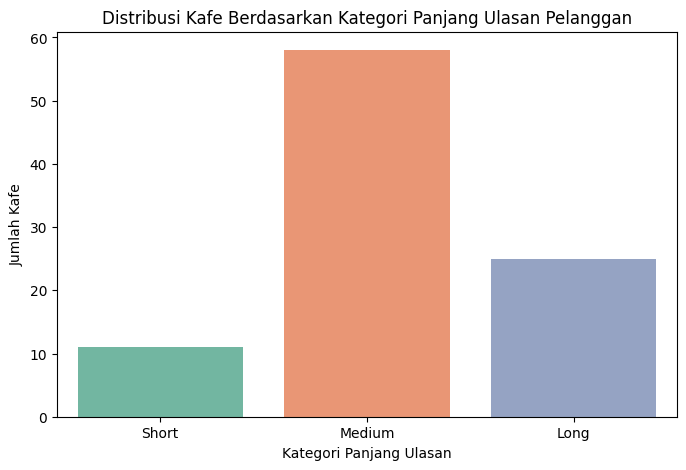

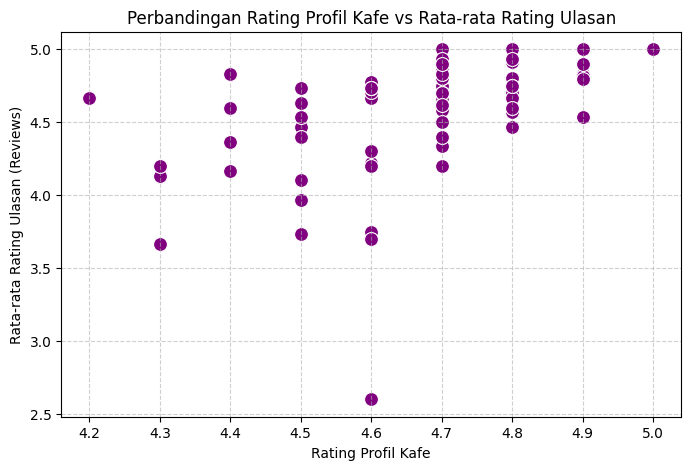

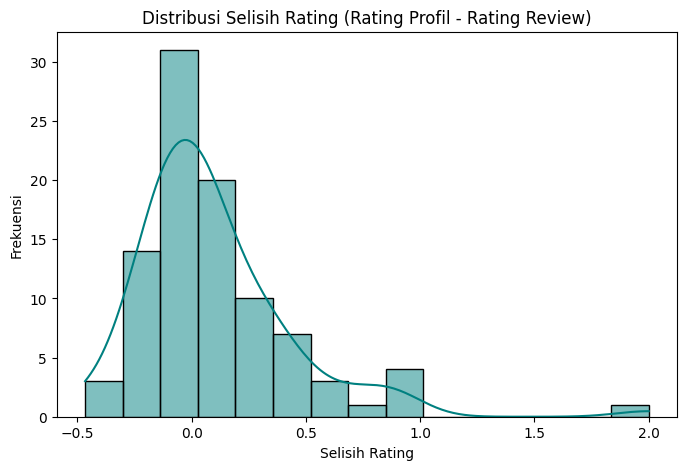

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# === VISUALISASI 1: Distribusi Kategori Panjang Ulasan (ReviewLengthCategory) ===
plt.figure(figsize=(8, 5))
sns.countplot(x="ReviewLengthCategory", data=df_combined, palette="Set2", order=['Short', 'Medium', 'Long'])
plt.title("Distribusi Kafe Berdasarkan Kategori Panjang Ulasan Pelanggan")
plt.xlabel("Kategori Panjang Ulasan")
plt.ylabel("Jumlah Kafe")
plt.show()

# === VISUALISASI 2: Hubungan antara Rating Profil dan Rata-rata Rating Review ===
plt.figure(figsize=(8, 5))
sns.scatterplot(x="rating", y="avg_review_rating", data=df_combined, color="purple", s=100)
plt.title("Perbandingan Rating Profil Kafe vs Rata-rata Rating Ulasan")
plt.xlabel("Rating Profil Kafe")
plt.ylabel("Rata-rata Rating Ulasan (Reviews)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

# === VISUALISASI 3: Distribusi Selisih Rating (rating_diff) ===
plt.figure(figsize=(8, 5))
sns.histplot(df_combined['rating_diff'].dropna(), bins=15, kde=True, color="teal")
plt.title("Distribusi Selisih Rating (Rating Profil - Rating Review)")
plt.xlabel("Selisih Rating")
plt.ylabel("Frekuensi")
plt.show()